## Test Grid SANOS



The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


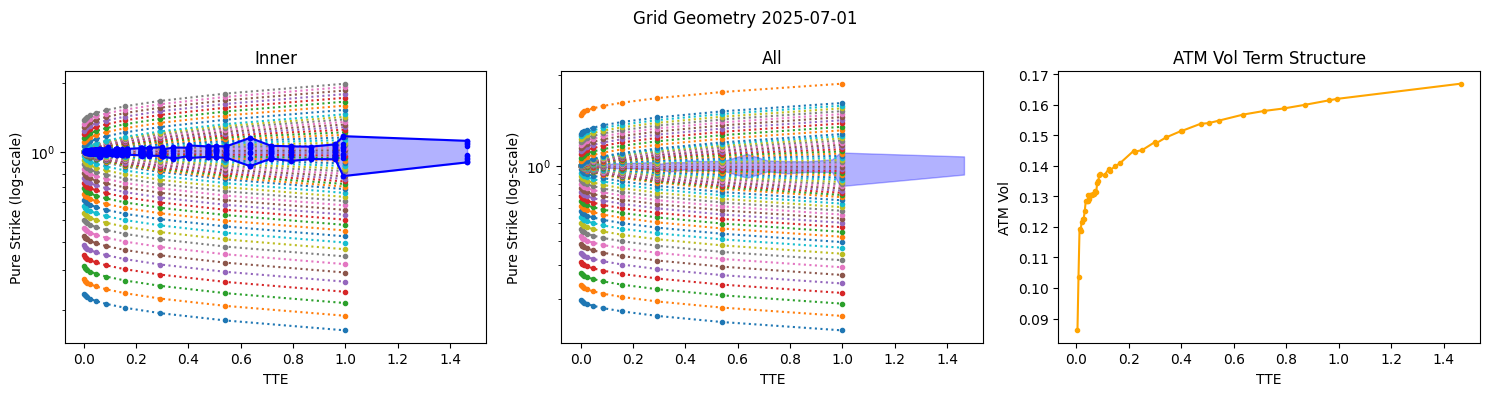

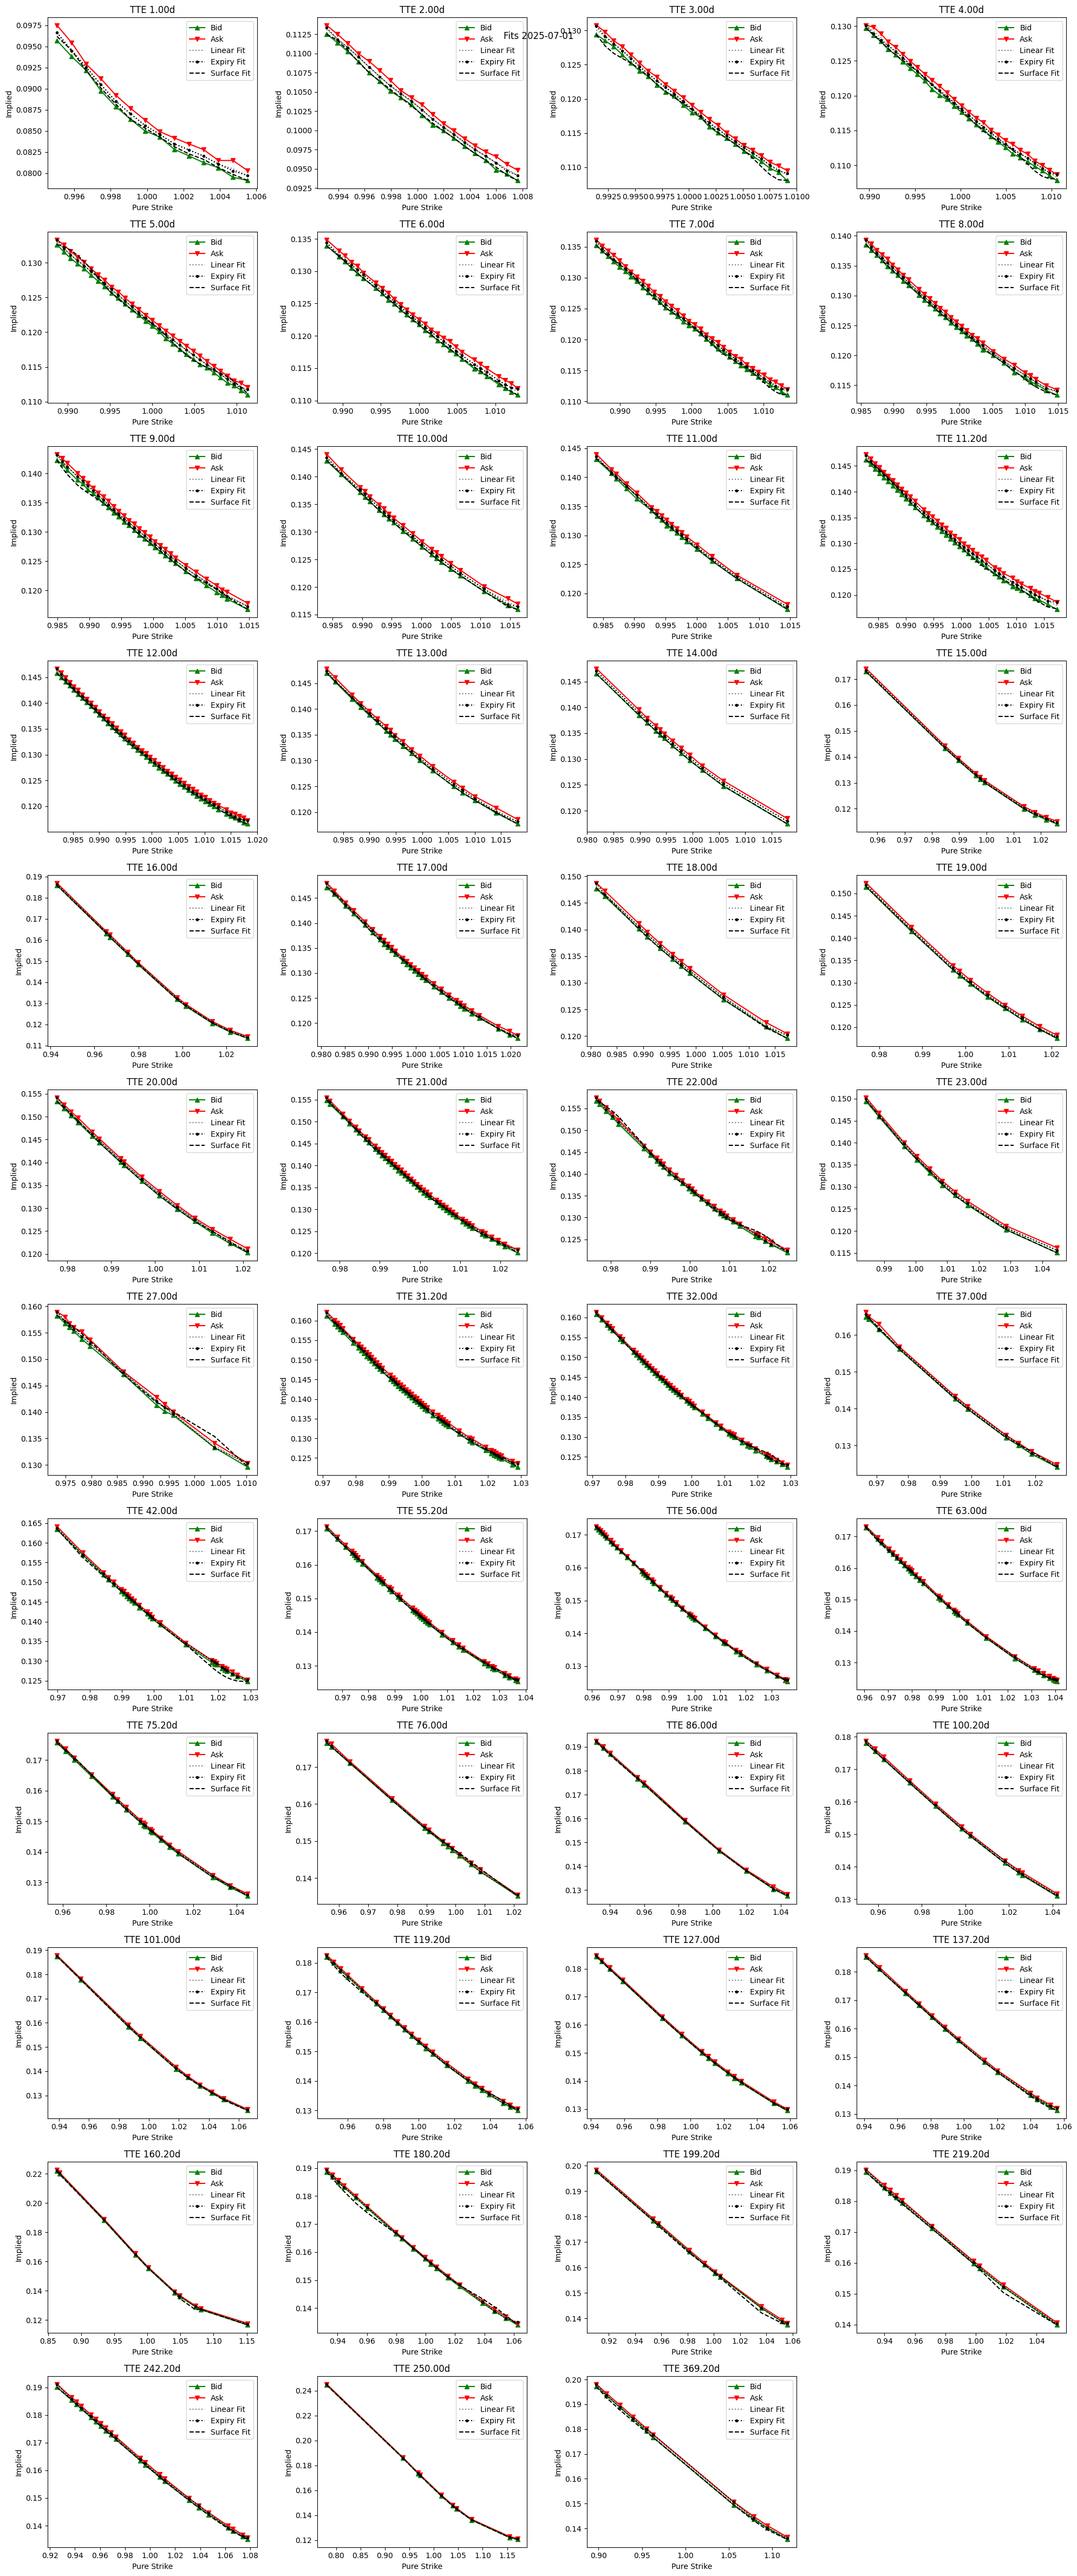

Running Surface Linear Arb-Free
00: Surface Arb-Free for 2025-07-01: Generated 47 0.01-smooth arbitrage-free expiries with extended strikes from 47 market expiries. This took 0.51s.
00: Surface Arb-Free for 2025-07-01: Finding 0.01-smooth arbitrage-free mid prices accross the entire surface of 445 strikes with a minimum strike distance of 0.000806... done. This took 0.39s.


In [7]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.utils.arbfree

from cdxcore.bs import bs
from cdxcore.dynaplot import figure, store
from cdxcore.verbose import Context
from quantdata.biz_calendar import DAYS_PER_YEAR, to_date
from quantdata.sanos.grid import GridGeometry, GridGeometryGenerator, GridSanos, BackboneNumpy
from quantdata.sanos.utils import extract_atm_fwd_vols
from quantdata.sanos.fitter import Eps, Fitter
from cdxcore.pretty import PrettyObject
import numpy as np

from quantdata.widb.options_filter import MkArbFree, RawDayFilter, ExpiryFilter, OptionsFilter, filter_options_day

def assess_fit(d, ticker = "SPX"):
    d = to_date(d)
    raw_day_filter = RawDayFilter()
    expiry_filter = ExpiryFilter()
    mk_arb_free = MkArbFree()
    options_filter = OptionsFilter()

    data = filter_options_day(ticker,d, mk_arb_free=mk_arb_free, options_filter=options_filter, raw_day_filter=raw_day_filter, expiry_filter=expiry_filter, verbose=Context.all )

    # construct grid
    # --------------

    grid        = GridGeometryGenerator(
                            horizon_t  = 1., 
                            num_times  = 10,
                            nms_range  = (-4,4),
                            num_nms    = 60,
                            dlv_min    = 0.01,
                            dlv_max    = 5.,
                            fwdvol_min = 0.0,
                            vol_interp = "lin_var",
                            lower_scale = 0.2,
                            upper_scale = 1.5
            ).create(dtype=np.float64)

    eps           = Eps()
    fitter        = Fitter( geometry = grid, eps = eps, debug=True, max_error = None, mid_fit_weight = 0. )
    sanos         = GridSanos( geometry = grid, bb = BackboneNumpy() )

    strikes       = data['pure_strike'].to_numpy()
    tte_y         = data['tte_y'].to_numpy()
    bid_vol       = data['bid_vol'].to_numpy()
    ask_vol       = data['ask_vol'].to_numpy()
    fit_vol       = data['fit1_vol'].to_numpy()
    bid           = data['pure_bid_price'].to_numpy()
    ask           = data['pure_ask_price'].to_numpy()
    arb_free_mask = data['mask_arb_free'].to_numpy()

    ixs = np.argsort(strikes)
    strikes = strikes[ixs]
    tte_y   = tte_y[ixs]
    bid_vol = bid_vol[ixs]
    ask_vol = ask_vol[ixs]
    fit_vol = fit_vol[ixs]
    bid     = bid[ixs]
    ask     = ask[ixs]
    del ixs

    # split into per-expiry
    # ---------------------

    afd = PrettyObject()

    afd.expiries = []
    afd.strikes  = []
    afd.bids     = []
    afd.asks     = []
    afd.fit_vols = []
    afd.ask_vols = []
    afd.mask     = []
    uttys        = np.unique(tte_y)

    for utty in uttys:
        mask = tte_y == utty
        afk = strikes[mask]
        assert np.all( np.diff(afk) > 0. ), f"Expected strikes to be strictly increasing for TTE {utty}, but found strikes {afk}"
        afd.mask.append(mask)
        afd.expiries.append( utty)
        afd.strikes.append( strikes[mask] )
        afd.bids.append( bid[mask] )
        afd.asks.append( ask[mask] )
        afd.fit_vols.append( fit_vol[mask] )
        afd.ask_vols.append( ask_vol[mask] )
    afd.expiries = np.array(afd.expiries)

    atm_vols    = MkArbFree.atm_volatilities( afd.expiries, afd.strikes, afd.ask_vols, fwdvol_min=0.01 )

    # plot the grid
    # -------------

    with figure(f"Grid Geometry {d}", col_size=5, row_size=4, columns=None ) as fig_strikes:
        axD, axA, axATM = fig_strikes.add_subplots("Inner", "All", "ATM Vol Term Structure")
        axD.set_xlabel("TTE")
        axA.set_xlabel("TTE")
        axATM.set_xlabel("TTE")
        axD.set_ylabel("Pure Strike (log-scale)")
        axA.set_ylabel("Pure Strike (log-scale)")
        axATM.set_ylabel("ATM Vol")
        axA.set_yscale("log")
        axD.set_yscale("log")

        axATM.plot( afd.expiries, atm_vols, ".-", color="orange" )

        for i in range(grid.N+2):
            axA.plot( grid.xexpiries, grid.xstrikes[:,i], ".:")
            if i>0 and i<grid.N-1:  
                axD.plot( grid.xexpiries, grid.xstrikes[:,i], ".:" )
                
        fig_strikes.render()
        store = fig_strikes.store()

        def plot_strikes(store):
            utty, inv = np.unique(tte_y, return_inverse=True)

            min_strike = np.full(len(utty), np.inf, dtype=strikes.dtype)
            max_strike = np.full(len(utty), -np.inf, dtype=strikes.dtype)

            np.minimum.at(min_strike, inv, strikes)
            np.maximum.at(max_strike, inv, strikes)
        
            store.clear()
            store += axA.fill_between(utty, min_strike, max_strike, alpha=0.3, color="blue")
            store += axD.fill_between(utty, min_strike, max_strike, alpha=0.3, color="blue")            
            store += axD.plot(utty, min_strike, ".-", color="blue")
            store += axD.plot(utty, max_strike, ".-", color="blue")
            store += axD.plot(tte_y, strikes, ".", color="blue")
            fig_strikes.render()

            return utty, min_strike, max_strike

        plot_strikes(store)

    with figure(f"Fits {d}", col_size=5, row_size=4, columns=4 ) as fig_fits:

        uttys = np.unique(tte_y)
        axs   = []
        for utty in uttys:
            mask = tte_y == utty
            ax = fig_fits.add_subplot(f"TTE {utty*DAYS_PER_YEAR:.2f}d")
            axs.append(ax)
            ax.set_xlabel("Pure Strike")
            ax.set_ylabel("Implied")

            istrike = strikes[mask]
            assert np.min( np.diff(istrike) ) > 0., f"Expected strikes to be strictly increasing for TTE {utty}, but found strikes {istrike}"

            ax.plot(istrike, bid_vol[mask], "^-", color="green", label="Bid")
            ax.plot(istrike, ask_vol[mask], "v-", color="red", label="Ask")
            ax.plot(istrike, fit_vol[mask], ":", color="grey", label="Linear Fit")
            ax.legend()
        fig_fits.render()

        # Linear
        # -------
        print("Running Surface Linear Arb-Free")

        highs_options = dict(solver="qpasm", presolve="on")
        mk_arb_free = MkArbFree( "surface", smoothness=0.1**2, mid_fit_weight=0.1 )
#                                    cvxpy_solver = "HIGHS", cvxpy_solver_options = dict(highs_options=highs_options, warm_start=True) )


        af_expiries = []
        af_strikes  = []
        af_bids     = []
        af_asks     = []
        uttys       = np.unique(tte_y)
        af_mask     = []

        for utty in uttys:
            mask = tte_y == utty
            afk = strikes[mask]
            assert np.all( np.diff(afk) > 0. ), f"Expected strikes to be strictly increasing for TTE {utty}, but found strikes {afk}"
            af_mask.append(mask)
            af_expiries.append( utty)
            af_strikes.append( strikes[mask] )
            af_bids.append( bid[mask] )
            af_asks.append( ask[mask] )
        af_expiries = np.array(af_expiries)

        af = mk_arb_free(
                expiries       = af_expiries, 
                strikes        = af_strikes,
                bids           = af_bids,
                asks           = af_asks,
                vols           = atm_vols,
                handle_arb     = "warn", # how to handle arbitrage situations: "warn", "raise" or "ignore"
                message_context= lambda : f"Surface Arb-Free for {d}",
                verbose        = Context.all )

        afits1 = np.zeros_like(strikes)
        afitsX = np.zeros_like(strikes)
        afits_valid = np.zeros_like(strikes, dtype=bool)

        for afi, marketi in enumerate(af.input_index):
            mask = af_mask[marketi]
            assert tte_y[mask][0] == af.expiries[afi], f"Expected expiry {af.expiries[afi]} for market index {marketi} but found {tte_y[mask][0]}"

            afits_valid[mask] = True
            afits1[mask] = af.fits1[afi]
            afitsX[mask] = af.fitsX[afi]
            assert np.allclose(afits1[mask], af.fits1[afi])

        afits_vol1 = bs.implied(strikes, afits1, sqrtT = np.sqrt(tte_y), mask= afits_valid )
        afits_volX = bs.implied(strikes, afitsX, sqrtT = np.sqrt(tte_y), mask= afits_valid )

        for utty, ax in zip( uttys, axs ):
            mask = tte_y == utty
            assert np.all( afits_valid[mask] ) or np.all( ~afits_valid[mask] )
            af_valid = np.any( afits_valid[mask] )
            istrike  = strikes[mask]
            assert np.min( np.diff(istrike) ) > 0., f"Expected strikes to be strictly increasing for TTE {utty}, but found strikes {istrike}"

            if af_valid:
                ax.plot(istrike, afits_vol1[mask], ".:", color="black", label="Expiry Fit")
                ax.plot(istrike, afits_volX[mask], "--", color="black", label="Surface Fit")
                ax.legend()
        fig_fits.render()

        return af

af = assess_fit("2025-07-01")



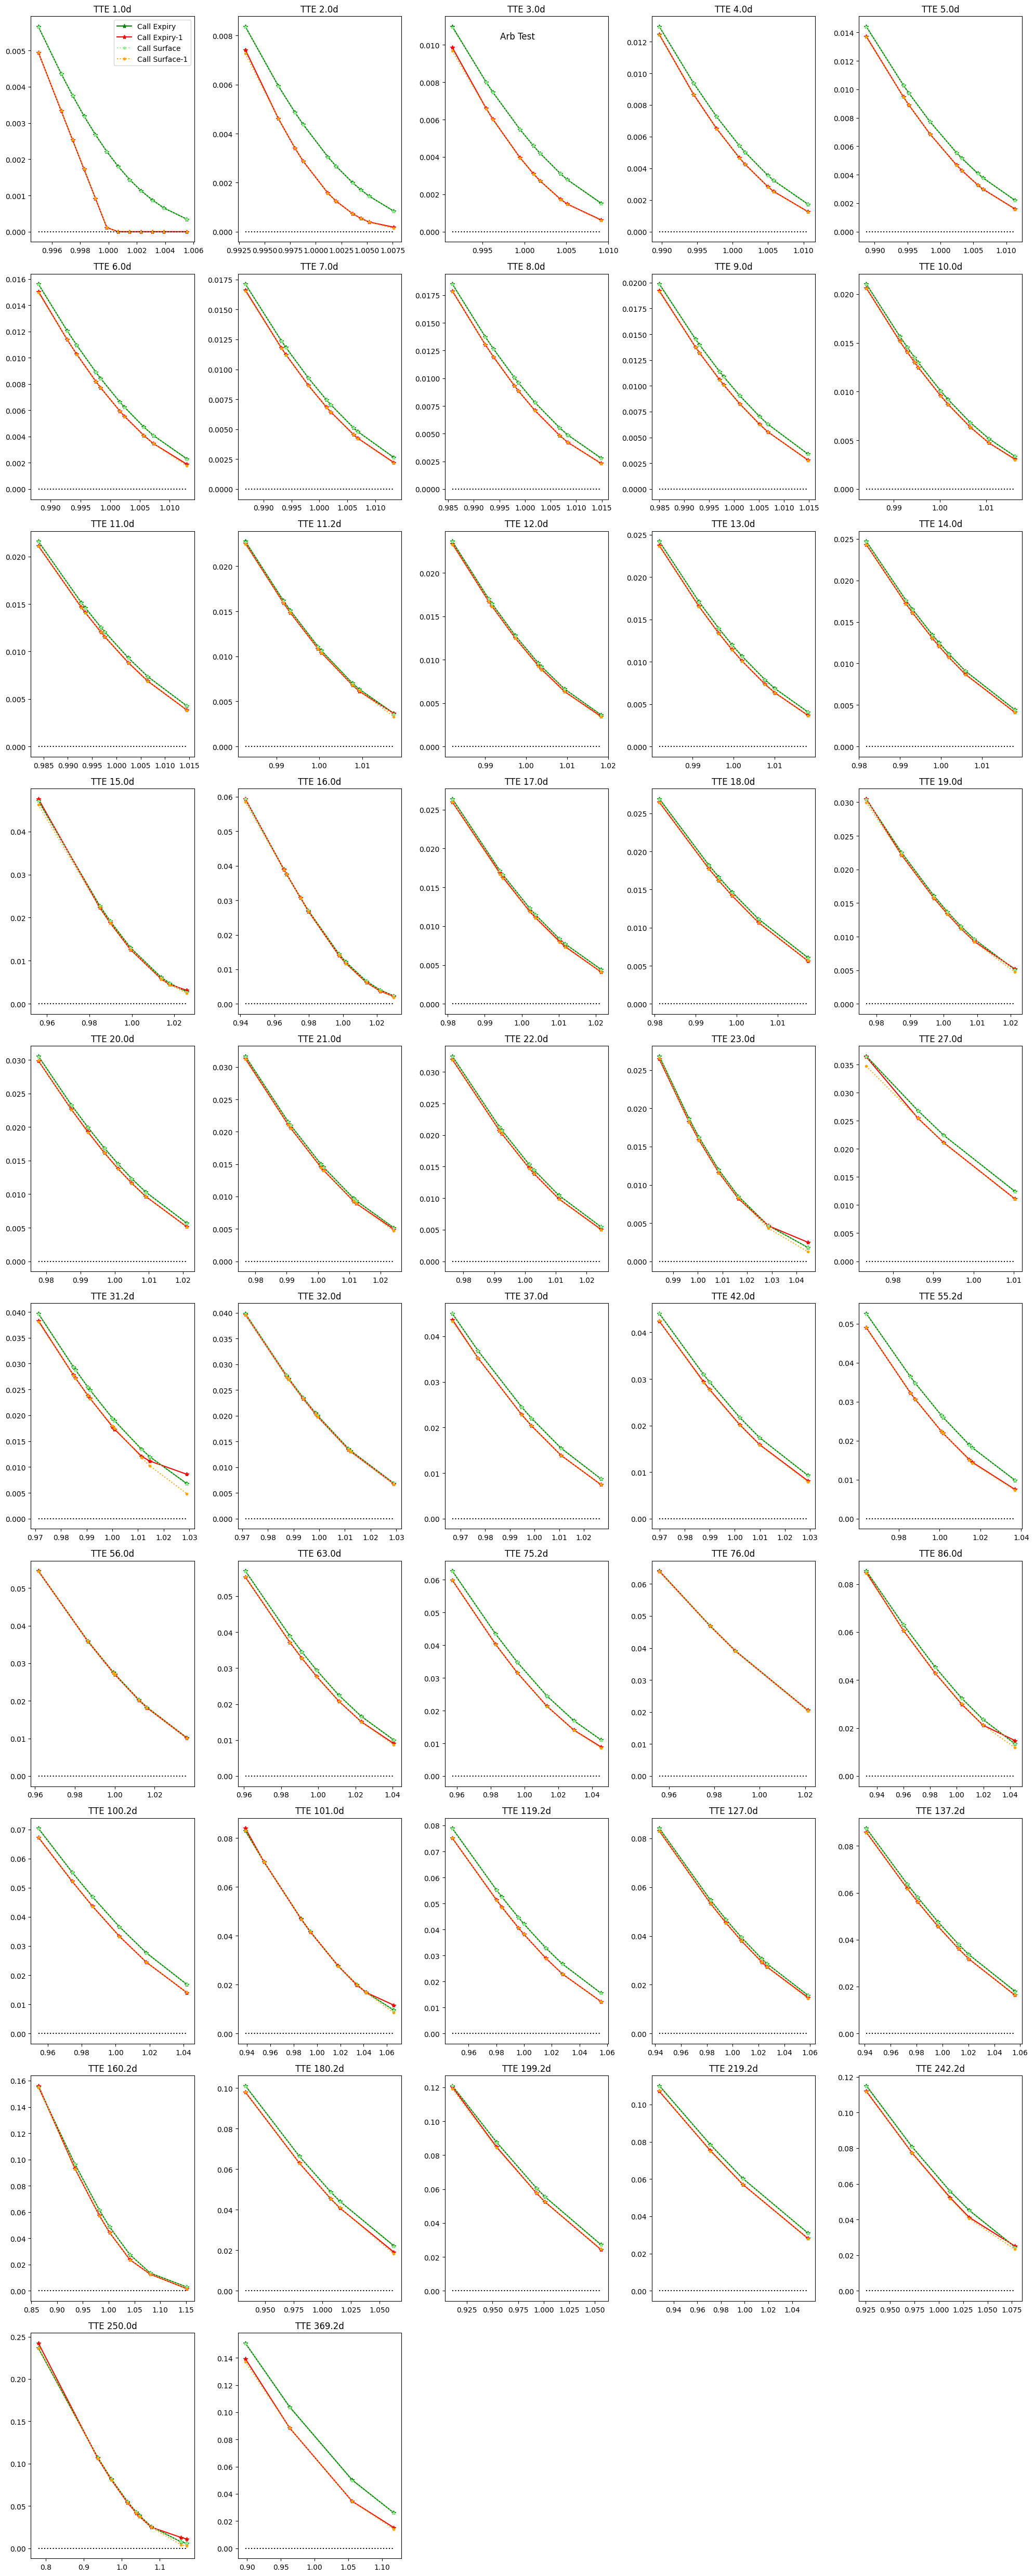

In [8]:
def arb_test(af):

    with figure("Arb Test") as fig:

        T = len(af.expiries)
        for t in range(T):
            expiry_tm1 = af.expiries[t-1] if t>0 else 0.
            expiry     = af.expiries[t]
            xstrikes_t = af.xstrikes[t]

            call_tm1   = af.price( expiry_tm1, xstrikes_t[1:-1], mode="expiry") 
            call_t     = af.price( expiry, xstrikes_t[1:-1], mode="expiry") 
            scall_tm1  = af.price( expiry_tm1, xstrikes_t[1:-1], mode="surface") 
            scall_t    = af.price( expiry, xstrikes_t[1:-1], mode="surface") 

            ax = fig.add_subplot(f"TTE {expiry*DAYS_PER_YEAR:.1f}d")
            ax.plot( xstrikes_t[1:-1], call_t, "*-", color="green", label="Call Expiry" )
            ax.plot( xstrikes_t[1:-1], call_tm1, "*-", color="red", label="Call Expiry-1" )
            ax.plot( xstrikes_t[1:-1], scall_t, ".:", color="lightgreen", label="Call Surface" )
            ax.plot( xstrikes_t[1:-1], scall_tm1, ".:", color="orange", label="Call Surface-1" )
            ax.plot( xstrikes_t[1:-1], xstrikes_t[1:-1]*0., ":", color="black")
            if t==0:
                ax.legend()

arb_test(af)




